# AML Transaction Classification – Model Training & Evaluation

**Project:** Money Laundering Detection

**Objective:** Train and compare machine learning models to classify transactions as legitimate or potentially related to money laundering.

This notebook focuses on:
- Loading prepared training, validation, and test datasets.
- Loading the preprocessing pipeline.
- Training and comparing machine learning models.
- Optimizing classification thresholds.
- Evaluating final model performance.

## 1. Import Libraries & Load Dataset

Import the required libraries and load the prepared dataset.


# Import Libraries & Load Preprocessing Artifacts

In [1]:
# Install model libraries
%pip -q install xgboost catboost

# Standard libraries
import zipfile
from pathlib import Path

# Data handling
import pandas as pd
import numpy as np
import joblib

# Visualization
import matplotlib.pyplot as plt

# Machine learning
from sklearn.base import clone
from sklearn.pipeline import Pipeline

# Models
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    average_precision_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Google Colab
from google.colab import files
from IPython.display import display


# Upload preprocessing artifacts
uploaded = files.upload()

archive_name = "aml_preprocessing_artifacts.zip"

if archive_name not in uploaded:
    raise FileNotFoundError(
        f"{archive_name} was not uploaded."
    )

# Extract artifacts
with zipfile.ZipFile(archive_name, "r") as zipf:
    zipf.extractall("aml_preprocessing_artifacts")

data_dir = Path("aml_preprocessing_artifacts")


# Load prepared datasets
X_train = pd.read_csv(data_dir / "X_train.csv")
X_val = pd.read_csv(data_dir / "X_val.csv")
X_test = pd.read_csv(data_dir / "X_test.csv")

y_train = pd.read_csv(data_dir / "y_train.csv")["Is_laundering"]
y_val = pd.read_csv(data_dir / "y_val.csv")["Is_laundering"]
y_test = pd.read_csv(data_dir / "y_test.csv")["Is_laundering"]

# Load preprocessing pipeline
preprocessor = joblib.load(
    data_dir / "preprocessor.joblib"
)

print("Prepared datasets loaded successfully!")

Saving aml_preprocessing_artifacts.zip to aml_preprocessing_artifacts.zip
Prepared datasets loaded successfully!


In [2]:
expected_features = [
    "Day",
    "Payment_currency",
    "Received_currency",
    "Sender_bank_location",
    "Receiver_bank_location",
    "Payment_type",
    "Amount",
    "is_payment_same",
    "is_bank_same_location",
    "hour_sin",
    "hour_cos"
]

assert X_train.columns.tolist() == expected_features
assert X_val.columns.tolist() == expected_features
assert X_test.columns.tolist() == expected_features

print("Feature configuration verified successfully!")

Feature configuration verified successfully!


# Verify Loaded Datasets

In [3]:
# Verify dataset dimensions

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nTarget shapes:")
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)


# Verify feature consistency
assert X_train.columns.equals(X_val.columns)
assert X_train.columns.equals(X_test.columns)

# Verify feature and target lengths
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

# Verify target values
for name, target in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    if target.isna().any():
        raise ValueError(f"Missing target values in {name} set.")

    if not target.isin([0, 1]).all():
        raise ValueError(f"Invalid target values in {name} set.")

print("\nDataset verification passed!")

print("\nSelected features:")
print(X_train.columns.tolist())

Training set: (58239, 11)
Validation set: (19413, 11)
Test set: (19414, 11)

Target shapes:
y_train: (58239,)
y_val: (19413,)
y_test: (19414,)

Dataset verification passed!

Selected features:
['Day', 'Payment_currency', 'Received_currency', 'Sender_bank_location', 'Receiver_bank_location', 'Payment_type', 'Amount', 'is_payment_same', 'is_bank_same_location', 'hour_sin', 'hour_cos']


## Train Random Forest

Train Random Forest as the baseline model. Class weighting is used to account for class imbalance.


In [4]:
rf_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


## Train XGBoost

Train XGBoost using the same training data and preprocessing approach.


In [5]:
# Calculate class imbalance ratio from training data only

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Scale positive weight:", round(scale_pos_weight, 4))


# Train XGBoost

xgb_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost training completed.")

Scale positive weight: 3.3175
XGBoost training completed.


## Train CatBoost

Train CatBoost with class balancing. In this implementation, categorical variables are imputed and One-Hot Encoded before being passed to CatBoost; native categorical processing is not used here.


In [6]:
# Train CatBoost

cat_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", CatBoostClassifier(
        iterations=800,
        depth=6,
        learning_rate=0.03,
        l2_leaf_reg=5,
        auto_class_weights="Balanced",
        eval_metric="PRAUC",
        random_seed=42,
        verbose=0,
        allow_writing_files=False
    ))
])

cat_model.fit(X_train, y_train)

print("CatBoost training completed.")

CatBoost training completed.


## Evaluate Model Ranking Performance on Validation Data

Calculate threshold-independent metrics for all models:
- Average Precision (reported here as PR-AUC).
- ROC-AUC.

These metrics evaluate how well each model ranks positive cases above negative cases, independent of the selected classification threshold.


In [7]:
# Evaluate model ranking performance

models = {
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "CatBoost": cat_model
}

validation_ranking_results = []
models_probabilities = {}

for model_name, trained_model in models.items():

    val_prob = trained_model.predict_proba(X_val)[:, 1]
    models_probabilities[model_name] = val_prob

    validation_ranking_results.append({
        "Model": model_name,
        "PR-AUC (Average Precision)": average_precision_score(
            y_val, val_prob
        ),
        "ROC-AUC": roc_auc_score(y_val, val_prob)
    })

validation_ranking_df = pd.DataFrame(validation_ranking_results)

display(
    validation_ranking_df.style.format({
        "PR-AUC (Average Precision)": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

,Model,PR-AUC (Average Precision),ROC-AUC
0,Random Forest,0.6740,0.8789
1,XGBoost,0.7243,0.8999
2,CatBoost,0.7567,0.9253


## Threshold Optimization on Validation Data

A common operating requirement is applied to all models:

**Minimum Recall = 0.75**

For each model, thresholds from 0.01 to 0.99 are evaluated. Among thresholds satisfying the Recall requirement, the selected threshold maximizes Precision; F1-score is used as a tie-breaker.

The test set is not used for threshold selection.


In [8]:
# Define minimum recall requirement

minimum_recall = 0.75

threshold_values = np.round(
    np.arange(0.01, 1.00, 0.01), 2
)

threshold_results = []

for model_name, probabilities in models_probabilities.items():

    for threshold in threshold_values:

        predictions = (probabilities >= threshold).astype(int)

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_val, predictions, zero_division=0
            )
        })

threshold_df = pd.DataFrame(threshold_results)


# Keep thresholds satisfying the minimum Recall requirement

eligible_results = threshold_df[
    threshold_df["Recall"] >= minimum_recall
].copy()

if eligible_results.empty:
    raise ValueError(
        "No model satisfies the minimum Recall requirement."
    )


# Select the best threshold for each eligible model

best_thresholds = (
    eligible_results
    .sort_values(
        ["Model", "Precision", "F1-score"],
        ascending=[True, False, False]
    )
    .groupby("Model")
    .head(1)
    .sort_values(
        ["F1-score", "Precision"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

print(
    f"Best threshold for each model "
    f"(Recall >= {minimum_recall}):"
)

display(
    best_thresholds.style.format({
        "Threshold": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)

Best threshold for each model (Recall >= 0.75):


,Model,Threshold,Precision,Recall,F1-score
0,CatBoost,0.57,0.6709,0.7591,0.7123
1,XGBoost,0.52,0.5993,0.7522,0.6671
2,Random Forest,0.28,0.5574,0.7649,0.6449


## Model Comparison & Selection

Compare the best validation operating point for each model under the same minimum Recall requirement.

The model with the highest F1-score is selected, using Precision as a tie-breaker, while satisfying the minimum Recall requirement.

In [9]:
# Compare eligible models

comparison_table = best_thresholds[
    ["Model", "Threshold", "Precision", "Recall", "F1-score"]
].copy()

comparison_table = comparison_table.sort_values(
    ["F1-score", "Precision"],
    ascending=[False, False]
).reset_index(drop=True)

print("Model comparison based on validation results:")

display(
    comparison_table.style.format({
        "Threshold": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)


# Select the best-performing model

selected_model_row = comparison_table.iloc[0]

selected_model_name = selected_model_row["Model"]

final_model = models[selected_model_name]

final_threshold = float(
    selected_model_row["Threshold"]
)

print("\nSelected model:", selected_model_name)
print("Selected threshold:", final_threshold)

Model comparison based on validation results:


,Model,Threshold,Precision,Recall,F1-score
0,CatBoost,0.57,0.6709,0.7591,0.7123
1,XGBoost,0.52,0.5993,0.7522,0.6671
2,Random Forest,0.28,0.5574,0.7649,0.6449



Selected model: CatBoost
Selected threshold: 0.57


## Final Evaluation on Test Set

Evaluate the selected model once on the held-out test set using the classification threshold selected from validation.

The test set is used only for final evaluation and must not influence model selection or threshold optimization.


In [10]:
# Predict probabilities on the test set

test_prob = final_model.predict_proba(X_test)[:, 1]


# Apply the threshold selected using validation data

test_pred = (test_prob >= final_threshold).astype(int)


# Calculate final test metrics

final_metrics = {
    "Model": selected_model_name,
    "Threshold": final_threshold,
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, test_pred, zero_division=0
    ),
    "PR-AUC (Average Precision)": average_precision_score(
        y_test, test_prob
    ),
    "ROC-AUC": roc_auc_score(y_test, test_prob)
}

final_results = pd.DataFrame([final_metrics])

print("Final Test Results:")

display(
    final_results.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "PR-AUC (Average Precision)": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


# Confusion Matrix

print("\nFinal Test Confusion Matrix:")
print(confusion_matrix(y_test, test_pred))


# Classification Report

print("\nFinal Test Classification Report:")

print(classification_report(
    y_test,
    test_pred,
    target_names=["Legitimate", "Laundering"],
    digits=4,
    zero_division=0
))

Final Test Results:


,Model,Threshold,Accuracy,Precision,Recall,F1-score,PR-AUC (Average Precision),ROC-AUC
0,CatBoost,0.57,0.8623,0.6748,0.7827,0.7247,0.7676,0.9285



Final Test Confusion Matrix:
[[13222  1696]
 [  977  3519]]

Final Test Classification Report:
              precision    recall  f1-score   support

  Legitimate     0.9312    0.8863    0.9082     14918
  Laundering     0.6748    0.7827    0.7247      4496

    accuracy                         0.8623     19414
   macro avg     0.8030    0.8345    0.8165     19414
weighted avg     0.8718    0.8623    0.8657     19414



## Confusion Matrix – CatBoost Test Set

Visualize the number of correctly and incorrectly classified transactions.


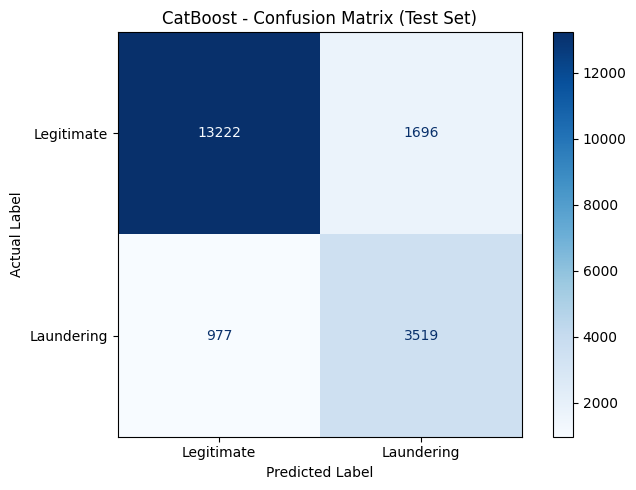

In [11]:
# Plot confusion matrix

cm = confusion_matrix(y_test, test_pred)

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Laundering"]
).plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title(
    f"{selected_model_name} - Confusion Matrix (Test Set)"
)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

## ROC Curve – CatBoost Test Set

The ROC curve illustrates the relationship between the True Positive Rate and False Positive Rate across classification thresholds.


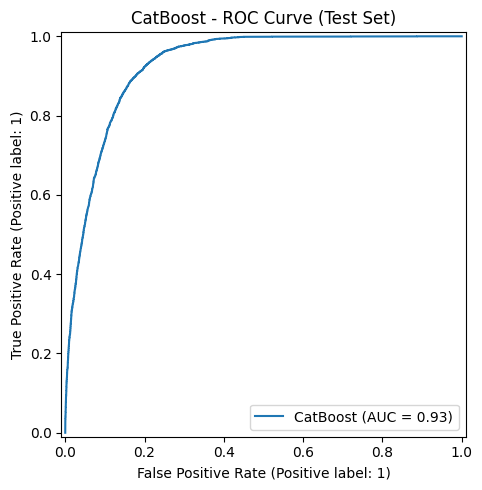

In [12]:
# Plot ROC curve

fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    test_prob,
    name=selected_model_name,
    ax=ax
)

ax.set_title(
    f"{selected_model_name} - ROC Curve (Test Set)"
)

plt.tight_layout()
plt.show()

## Precision-Recall Curve – CatBoost Test Set

The Precision-Recall curve illustrates the trade-off between Precision and Recall across classification thresholds. It is particularly informative when the target classes are imbalanced.


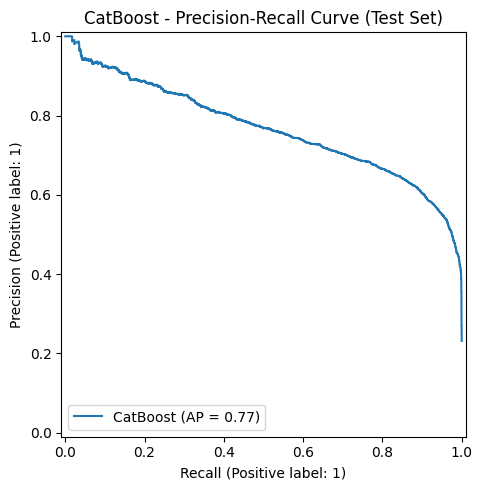

In [13]:
# Plot Precision-Recall curve

fig, ax = plt.subplots(figsize=(7, 5))

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_prob,
    name=selected_model_name,
    ax=ax
)

ax.set_title(
    f"{selected_model_name} - Precision-Recall Curve (Test Set)"
)

plt.tight_layout()
plt.show()

## Final Notes

- Three machine learning models were trained and compared: Random Forest, XGBoost, and CatBoost.
- All models used the same preprocessing pipeline.
- Model selection was based on validation performance.
- The selected operating threshold satisfied the minimum Recall requirement of 0.75.
- The test set was reserved for final evaluation only.
- PR-AUC is reported using scikit-learn's Average Precision metric.
- The dataset is synthetic; performance on real-world banking transactions may differ.